In [2]:
# steps to makemore using bigrams
# bigrams in words are two two that occur together
# in case of names we'll use two letters that occur together


# the pseudocode will be as follows

# read the names from name.txt
# prepare dataset of bigrams with xs as two letters and y as the letter after those 2
# split the dataset for training and testing
# count the total numbers of occurences of letter 

In [3]:
with open('names.txt') as f:
    words = f.read().splitlines()

In [4]:
# record the count of bigrams in a lookup table
import torch

In [5]:
N  = torch.ones((27, 27), dtype=torch.int32)

In [6]:
chars = sorted(list(set(''.join(words))))

In [7]:
stoi = {s:i + 1 for i, s in enumerate(chars)}
stoi['.'] = 0

itos = {i:s for s,i in stoi.items()}

In [8]:
for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        N[ix1, ix2] += 1

(np.float64(-0.5), np.float64(26.5), np.float64(26.5), np.float64(-0.5))

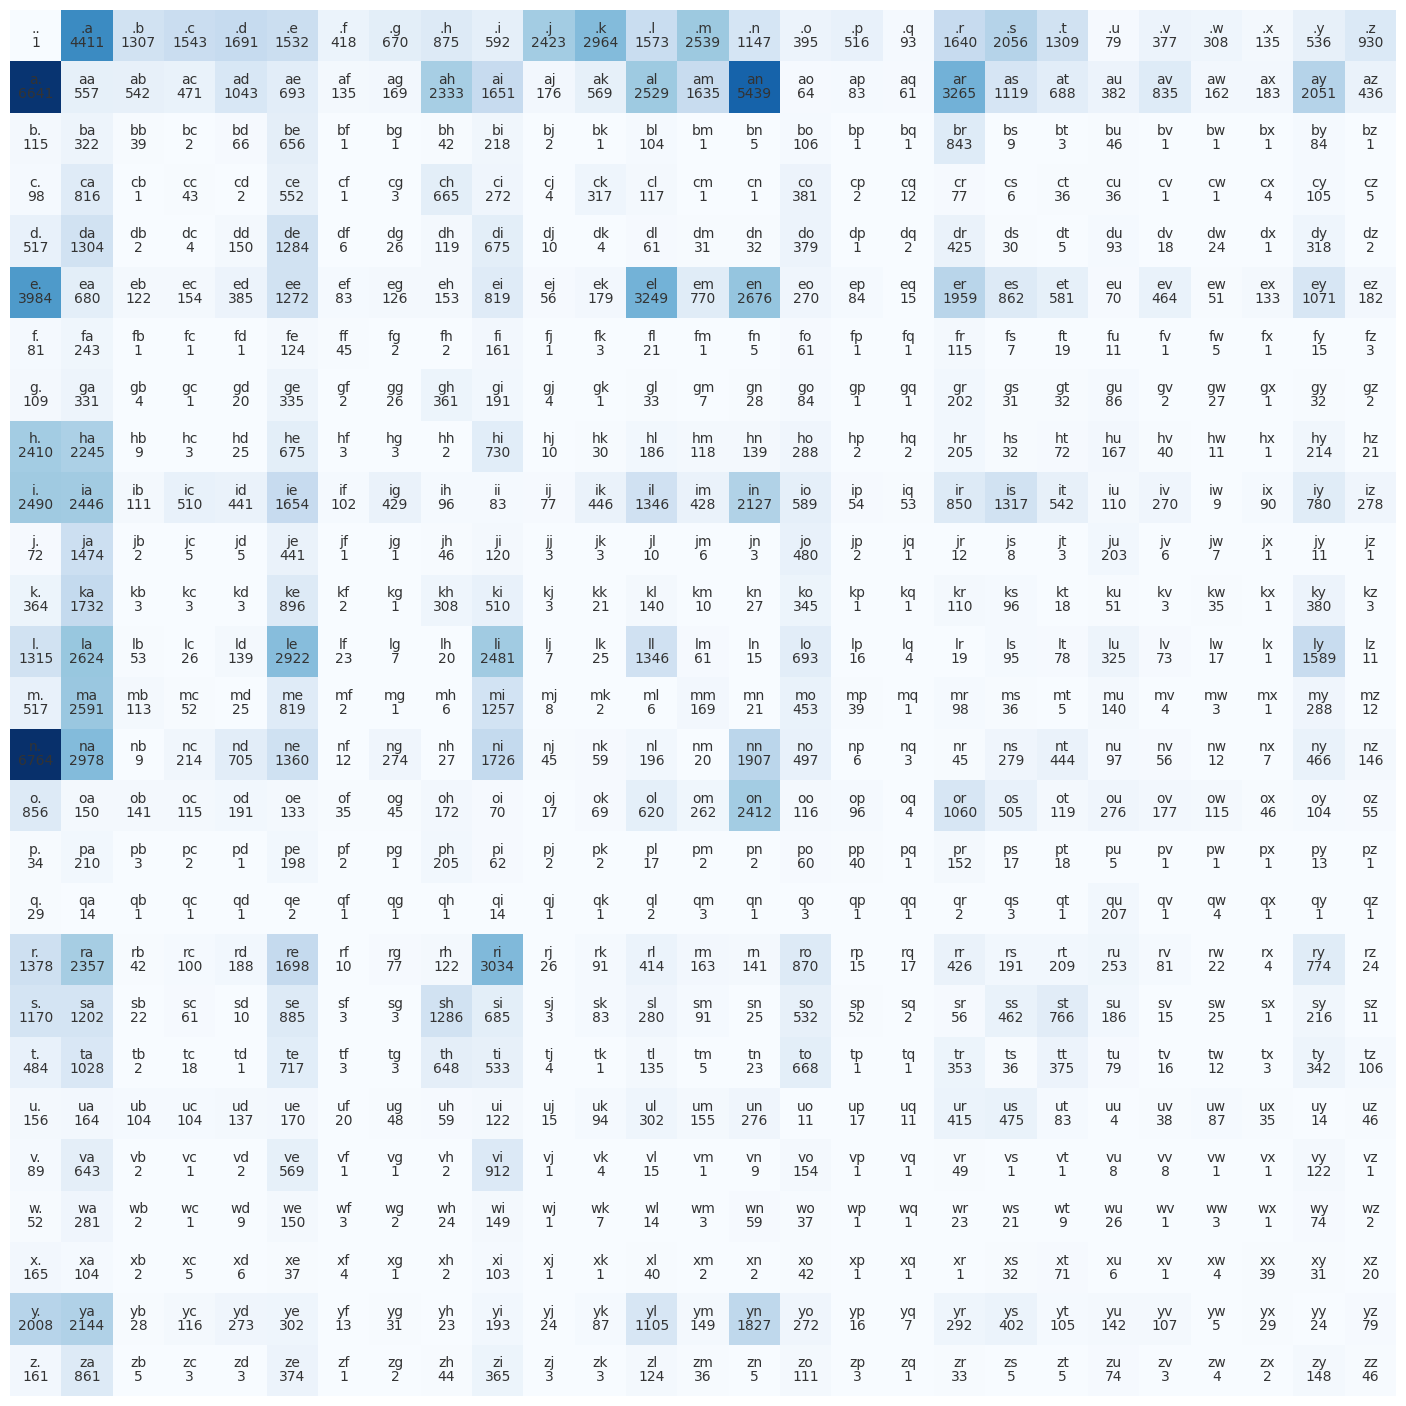

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 18))
plt.imshow(N, cmap='Blues')

for i in range(27):
    for j in range(27):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha='center', va='bottom', color=(.2, .2, .2))
        plt.text(j, i, N[i,j].item() , ha='center', va='top', color=(.2, .2, .2))
plt.axis(False) 

In [10]:
# create probability distribution from the count matrix
# to do so we divide the sum of counts in each row, with each counts in that row
P = N / N.sum(1, keepdim=True)

In [11]:
g = torch.Generator().manual_seed(47)

n_samples = 6

for i in range(n_samples):
    out = []
    ix = 0

    while True:
        p = P[ix]
        ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
        out.append(itos[ix])
        if ix==0:
            break
    print(''.join(out))

kylerynnajaa.
delorrush.
dran.
xada.
giahma.
labrr.


The same problem can be formulated as an optimization problem. This can be viewed as a neural net with input of onehot encoded character and outputing the softmax probabilities of each of the character minimizing the negalive log likelyhood loss. The architecture will be like   
(27 -> 27 -> 27)

In [26]:
# weights of the second layer.
w = torch.randn((27, 27), requires_grad=True)
# instead of one hot encoding we'll directly index into the correct row

# forward pass
def forward(ixs):
    # output n x 27 for each ix where n is the number of example inputs
    # return torch.vstack([w[ix] for ix in ixs]).softmax(dim=1)
    return w[ixs.int()].softmax(dim=1)

    # return w[ix].softmax(dim=-1)
    

# negative log likelyhood loss 
def NLLloss(y, y_pred):
    # in the dataset we have x, y pairs
    # where x is a letter and y  is the letter after it
    # loss is -log(predicted probability of letter y)
    # This works because the loss will be zero when the predicted probability of y is 1
    # for any other value of P(y) we'll get some negative value and -(negative value) will give us a positive loss
    # this is equivalent to maximizing the probability of letter y since log is a monotonically increasing function.
    
    # the inputs to the function are
    # y: a tensorof len n with the true ys
    # y_pred: a 2d tensor with  n x 27
    probs = -torch.log(y_pred.gather(dim=1, index = y.view(-1, 1)))
    return torch.mean(probs)
    


In [13]:
# dummy dataset
def dummy_test():
    X = ['a', 'b', 'c', 'd']
    y = ['n', 'e', 'a', 'o']

    X_enc = torch.tensor(list(stoi[x] for x in X), dtype=torch.int32)
    y_enc = torch.tensor(list(stoi[yi] for yi in y), dtype=torch.int32)
    # sanity check

    ypred = forward(X_enc)
    # get the
    probs = ypred.gather(dim=1, index=y_enc.view(-1, 1))
    loss = sum(-torch.log(probs))
    print(loss)
    print(NLLloss(y_enc, ypred))

In [14]:
dummy_test()

tensor([13.4718], grad_fn=<AddBackward0>)
tensor(3.3679, grad_fn=<MeanBackward0>)


In [23]:
# create dataset
X = []
y = []
for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        # ix1 = stoi[ch1]
        # ix2 = stoi[ch2]
        X.append(ch1) 
        y.append(ch2) 

In [24]:
X_enc = torch.tensor(list(stoi[x] for x in X), dtype=torch.long)
y_enc = torch.tensor(list(stoi[yi] for yi in y), dtype=torch.long)

In [20]:
X_enc[:9]

tensor([ 0,  5, 13, 13,  1,  0, 15, 12,  9])

In [28]:
# training loop
epochs = 100

for i in range(epochs):
    # forward
    y_pred = forward(X_enc)

    # loss
    loss = NLLloss(y_enc, y_pred)
    if i % 20 == 0:
        print(loss.item())

    # backward
    loss.backward()

    # step
    with torch.no_grad():
        w.data -= 11.5 * w.grad

    # zero gradient
    w.grad.zero_()

2.4719104766845703
2.471038818359375
2.470243453979492
2.469515800476074
2.4688475131988525


In [ ]:
# log likelyhood loss of the P table, the counting method
nll = 0
for i, xi in enumerate(X_enc):
    nll += P[xi, y_enc[i]].log()
-nll / len(X_enc)


tensor(2.4544)


So we'd expect the loss of the nn method to be same as the above loss, since we are enssentially estimating the same probability table, just using method of optimization.  
Which we do get
- loss from nn : 2.4588
- loss from counting : 2.4544

In [ ]:
@torch.no_grad()
def predict():
    X = ['a', 'b', 'c', 'd']

    X_enc = torch.tensor(list(stoi[x] for x in X), dtype=torch.int32)
    # sanity check

    ypred = forward(X_enc)
    idxs = ypred.max(dim=1).indices
    # return idxs
    return [itos[i.item()] for i in idxs]

In [ ]:
predict()

['.', 'r', 'a', 'a']

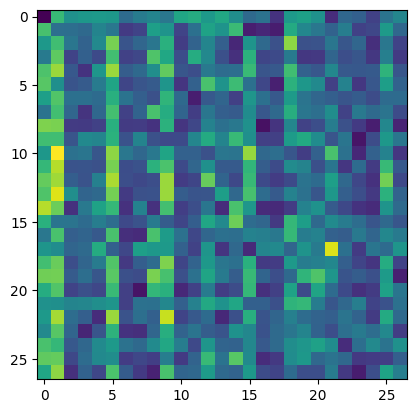

In [ ]:
# inference, generate namesw
import matplotlib.pyplot as plt
w_copy = torch.view_copy(w ,(27, 27)).detach().numpy()
plt.imshow(w_copy)

In [30]:
# sampling from the nn weights
g = torch.Generator().manual_seed(47)

n_samples = 6

for i in range(n_samples):
    out = []
    ix = 0

    while True:
        # using weights instead of the P table
        p = w[ix].softmax(dim=-1)
        ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
        out.append(itos[ix])
        if ix==0:
            break
    print(''.join(out))

kylerynnajaa.
delorrushcaran.
xhevigiahasalabrr.
brannmi.
baman.
kilyah.


Here we can see that using the same random see generator, the weight sof the nn are almost same as that of the counting method, and hence the first generated word is the same one. The later are different due to slight differences